## Data Manipulation

This project uses OpenRefine to filter, modify, and create new columns in the PAS_RS raw data. OpenRefine is an open-source tool develped by Google that helps manage messy data by cleaning, filtering, faceting, and transforming data tables. 

The raw data comes in a .txt file once downloaded from the National Archives, and is already organized by columns with vertical bars dividing the categories and record information. Although the data is preprocessed, the PAS_RS data contains a lot of columns with no values, and codes that need to be referenced or researched from the Readme document in order to understand its implications.

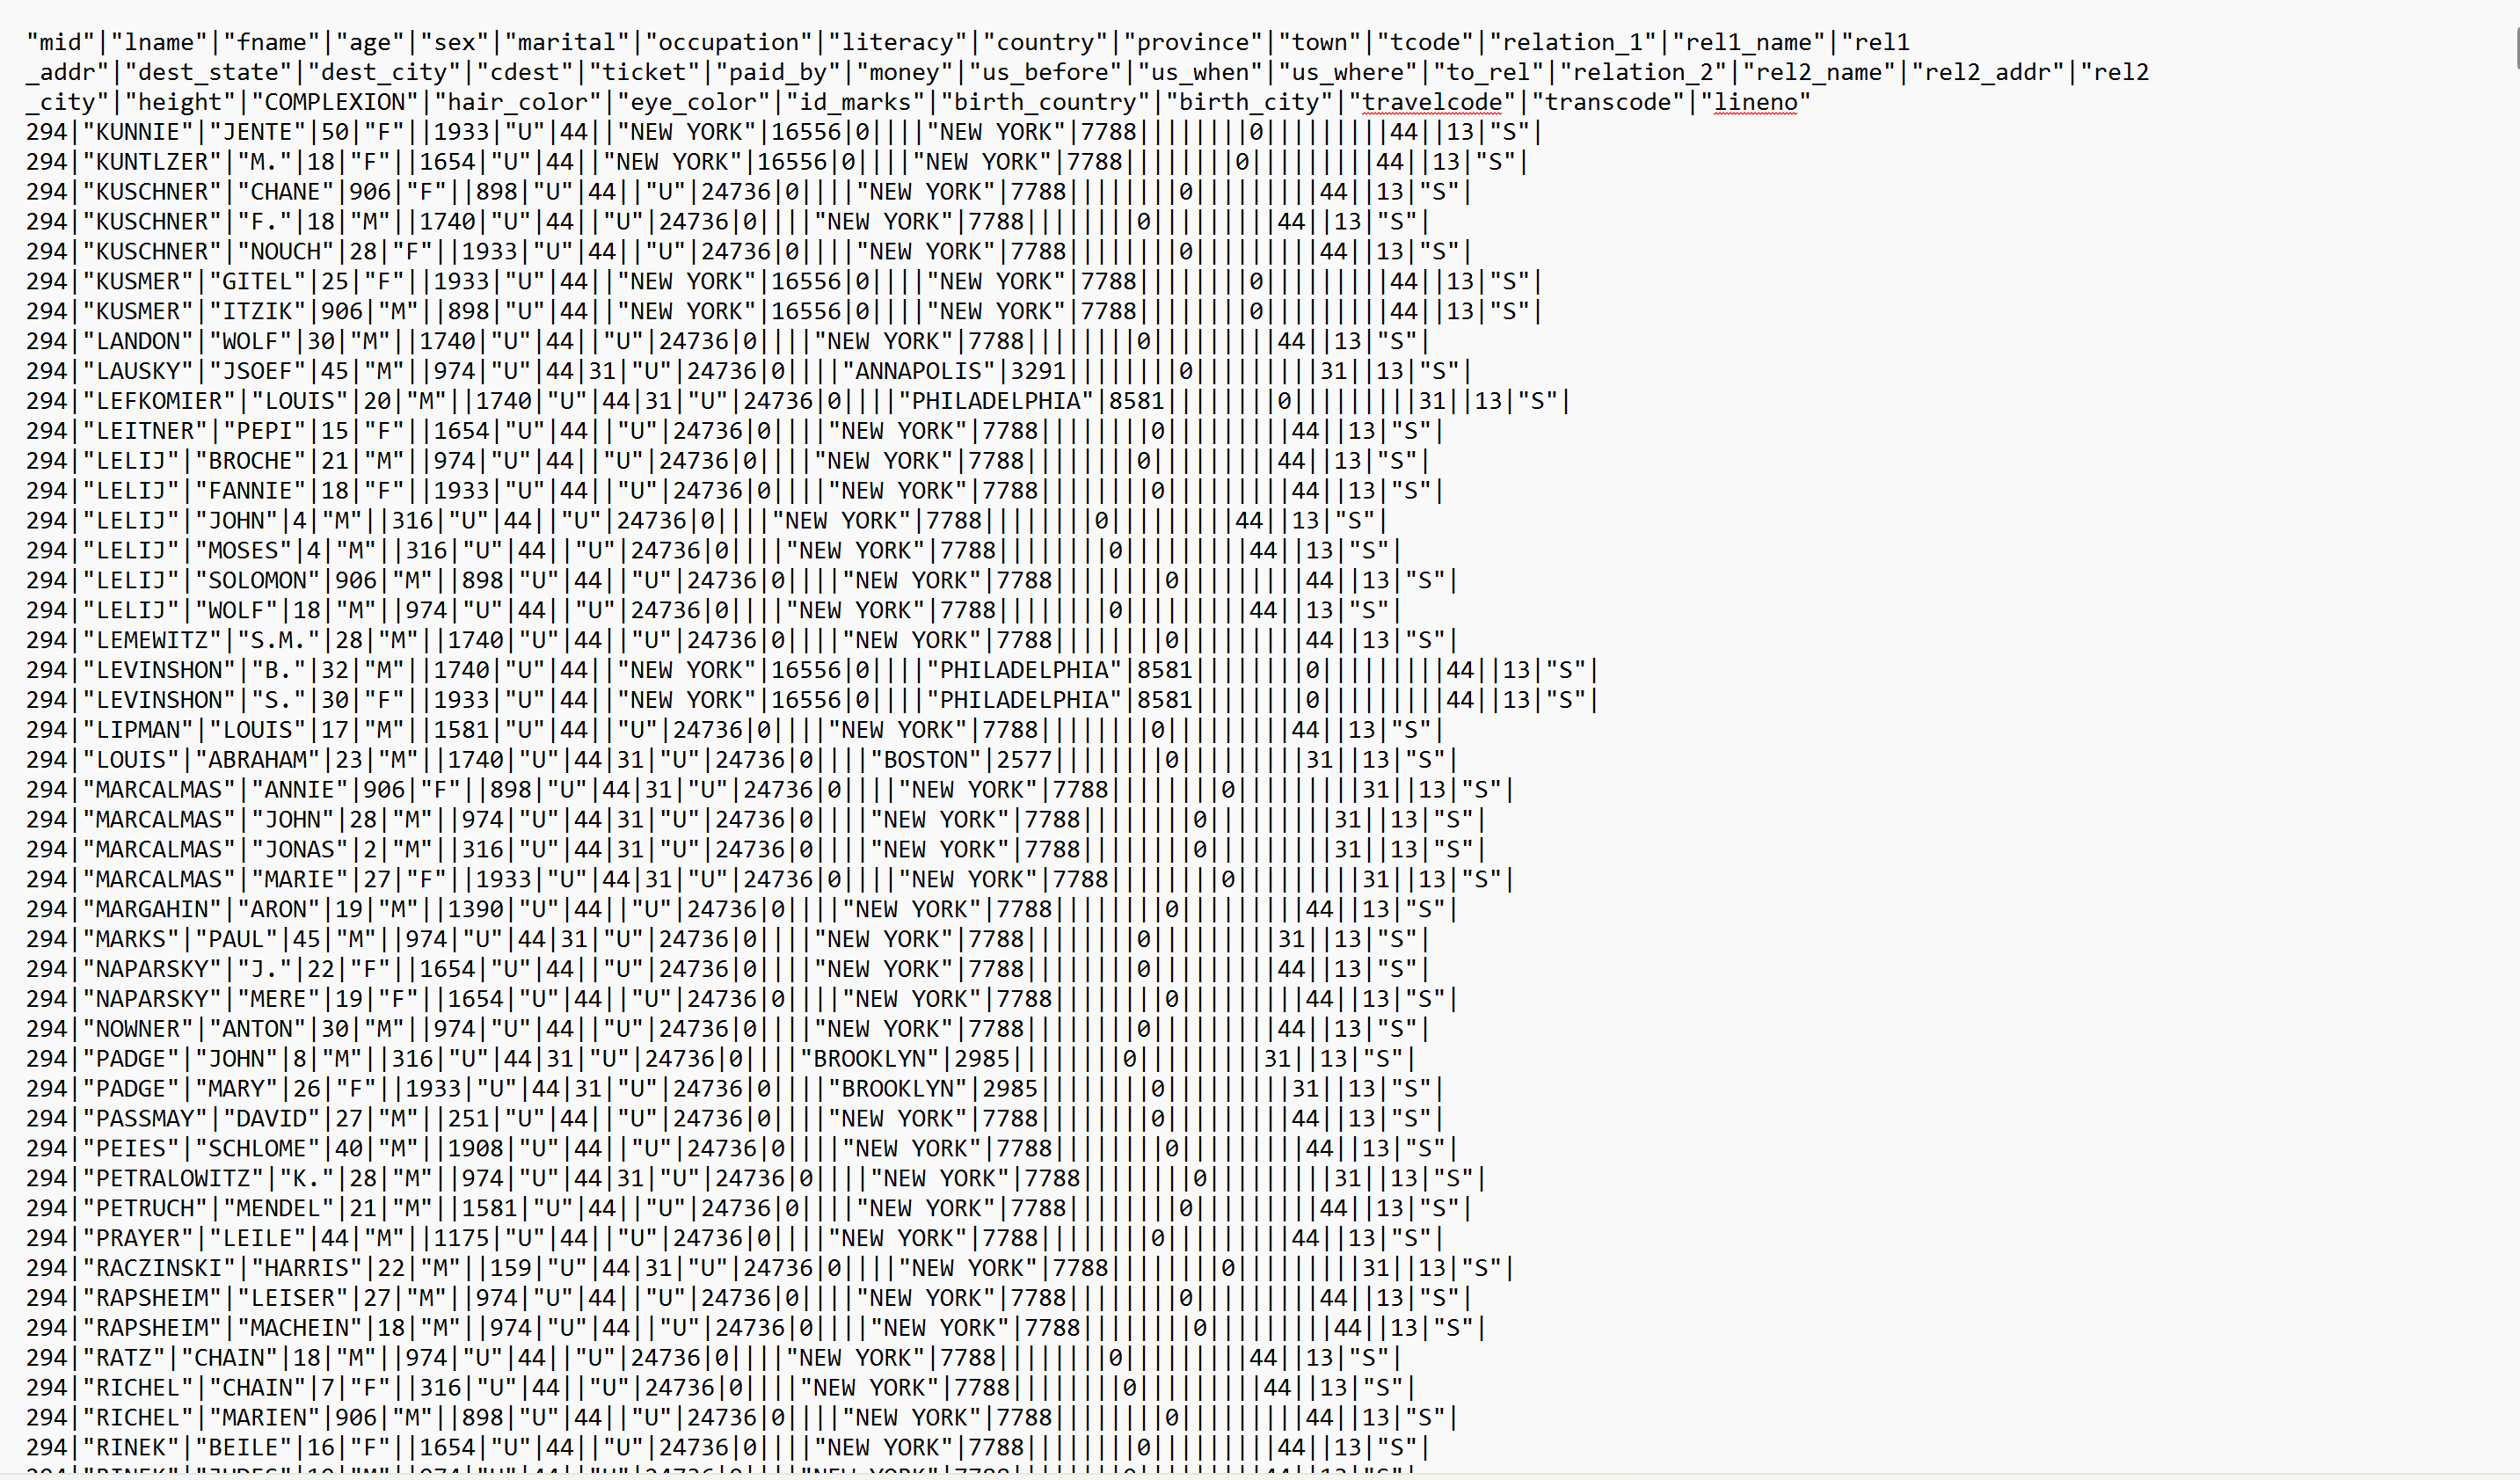

The data needs to be cleaned and clarified in order to improve understanding and use it for optimal analysis.

### OpenRefine

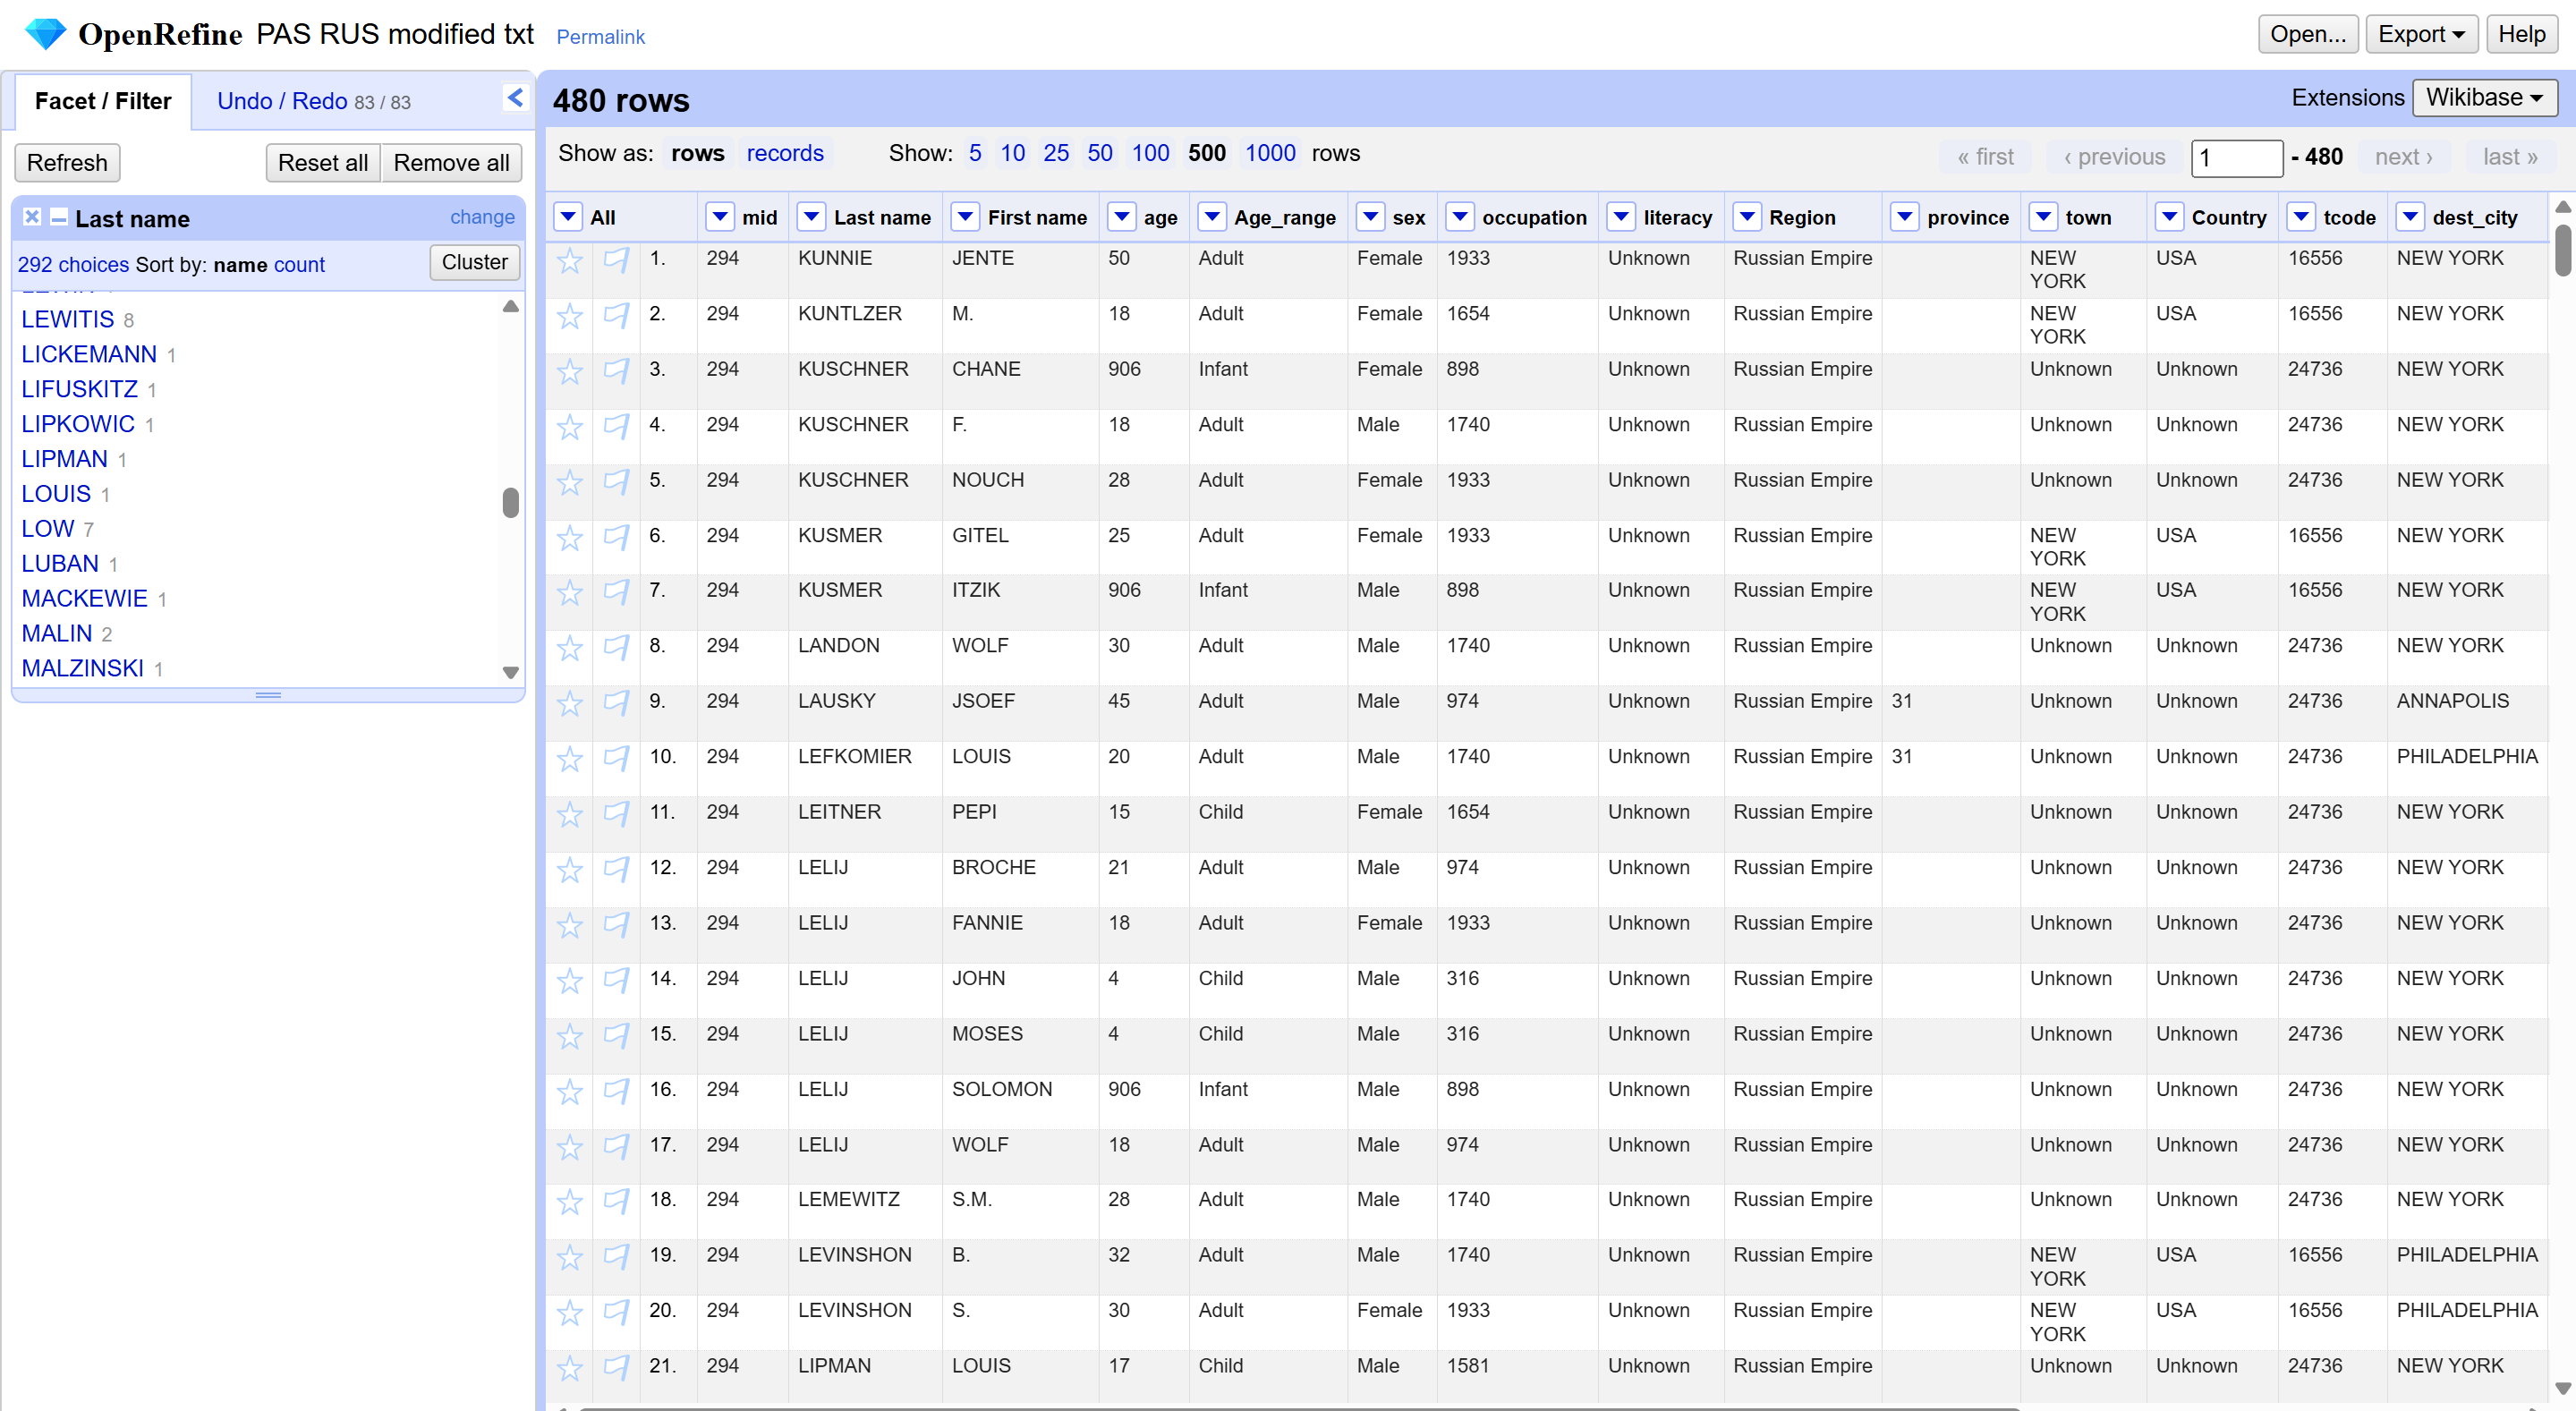

First, the first 480 records were extracted from PAS_RS.txt and moved into a new file titled PAS_RS_modified.txt. This was done due to the limitations of the local machine used which couldn't process more than 500 records and open the data in OpenRefine. The following modifications were made PAS_RS_modified.txt with OpenRefine:

**Deleted all columns with blank information**

The following columns were deleted because they yielded 0 or null results for the entire dataset:

* Marital
* Relation_1
* Rel1_name
* Rel1_addr
* dest_state
* Ticket
* Paid_by
* Money
* Us_before
* Us_when
* Us_where
* To_rel
* Relation_2
* Rel2_name
* Rel2_addr
* Rel2_city
* Height
* COMPLEXION
* Hair_color
* Eye_color
* Id_marks
* Birth_city
* lineno

These categories mainly attribute to relationships and phenotypes of the passengers. It would've been interesting analysing familial relations, economic statuses, and physical traits of passengers, however with nothing to go off of the columns had to be deleted.


**Edited data inputs and column names based on readme documentation**

The following data inputs were altered based on the codes and meanings listed in the readme documentation in order to enhance clarity (also used NotebookLM with inputted sources to identify obscure codes not clarified by readme, such as 44 attributing to Russian Empire and 13 as Scandinavia under the country column):
   
* Age: ‘800’ changed to ‘unknown’
* Sex: ‘M’ changed to ‘Male’, ‘F’ changed to ‘Female’
* Literacy rewritten into words, Y = Yes, N = No, U = Unknown
* Country: 44 changed to ‘Russian Empire’ which also encompasses Poland and Finland
* Province: 10 changed to ‘Finland’
* Town: ‘U’ changed to ‘Unknown’
* Travelcode: column name renamed to ‘accomodation’, ‘S’ changed into “Steerage” as accommodation of passenger on ship
* Transcode: ‘C’ changed into ‘Citizen of USA’, ‘S’ changed into ‘Staying in USA’, ‘R’ changed into ‘Return trip to USA (non US citizen)’, ‘T’ changed into ‘Returning to country of origin’

**Faceted location names**

Some names attributing to cities, provinces, and states were found to be entered differently. Automatic faceting tools within OpenRefine, and manual methods to catch discrepancies, were used to make changes within the following columns:

* Dest_city: PA and PENNSYLVANIA combined, seems to be both cities and states included but other acronyms of states will be left alone
* Town: clustered similar written town names such as ‘PETERSBURG’ and ‘ST.PETERSBURG’
  
**Adding columns to interpret present columns**

The following columns were added based off of established columns in order to convey interpretations:
<ol>
<li>Age_range: based on age column, ‘Infant’ given to values that contain 9xx based on readme, less than 18 labeled ‘Child’, and rest labeled ‘Adult’ code applied to column:

if(value.startsWith("90"), "Infant", if(value.toNumber() < 18, "Child", "Adult"))</li>

<li>Country: based on town column. Used google search to look up the town names listed in the town column. However there were key issues uncovered:
    
<ul>

<li>Names were heavily misspelled and didn’t match actual names in search, this can be interpreted as records collecting phonetic pronunciation or incorrect written spellings of passengers communicating their country of origin</li>
    
<li>Town names that didn’t yield reliable information were kept the same</li>

<li>Due to historical changes in names/boundaries, town names may not reflect/match current country that housed that town during that time</li>

</ul>

Based on these issues, the interpretation of the Country column are tentative and not fully reliable, but serve as a good overarching analysis on where passengers have come from

<li>Original ‘country’ column changed to ‘Region’, include ‘Russian Empire’ and ‘Scandinavia’ </li>
</ol>

The resulting dataset was then exported to an excel file that will be inputted into Tableau. The dataset can be viewed as a notebook below.


View dataset: [PAS_RUS final dataset](PAS-RUS-modified-txt.csv)


Next: [Visualization](Visualization.ipynb)